<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/08_year_check_andrew.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 4: how long does the model stay valid, and should year stay an input?

*AI-assisted: every code and markdown cell was generated with Claude (Opus 5.5) on 2026-11-10 and revised on 2026-11-11, and reviewed, run and edited by Andrew Reicin. None of this text is for the slides or report.*

Train the deployed tree (notebook 13) on games published up to **2016**, then test it on each later year (**2017 to 2021**) one at a time, as in Session 19's time split. Ground rule 2's random split does not apply here, and the model is not re-tuned.

- **Rows and inputs:** task 1's (notebook 05): games with no year or missing 4+ of the 8 inputs are dropped, the rest kept, with the two "list missing" flags and the median imputer fitted on the training years. As notebook 05's note for task 4 says, its random split is not used, and the common mechanics and categories are counted on the training years.
- **Model:** the deployed tree, notebook 05's settings (max_depth 12, min_samples_leaf 50).
- **Training years:** every kept game up to 2016.
- **2022 and 2023 left out:** the data was downloaded in January 2022, so those games were only rated by early raters.
- **Valid** is judged two ways: (a) error within 10% of the model's cross-validated error on its own training years; (b) R² above 0, i.e. better than guessing that year's average rating.
- Everything is run **with and without year of publication** as an input, and compared with notebook 04's random split (test RMSE 0.684 with year, 0.744 without).

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-11. Imports; reviewed and edited by Andrew Reicin.
# --- Andrew Reicin: Task 4, year-by-year test of how long the rating model stays valid, with and without year as an input ---
# [AI-assisted] Claude (Opus 5.5), 2026-11-10. Every code and markdown cell in this notebook was generated with Claude and reviewed, run and edited by Andrew Reicin.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

FIG_DIR = "../figures" if os.path.isdir("../figures") else "."
def save(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

COLORS = {"Year as an input": "tab:blue", "Year removed": "tab:orange", "Dummy (training mean)": "0.5"}

# Notebook 04's random split (its rows, its tree at depth 10 / leaf 50), test RMSE, for comparison
NB04_RANDOM = {"Year as an input": 0.684, "Year removed": 0.744}

## 1. Games and the year split

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-11. Load the data, apply task 1's row rule, and split by year; reviewed and edited by Andrew Reicin.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")

# ROWS: task 1's row rule (notebook 05, section 13): drop games with no year or missing 4+ of the 8 inputs; keep the rest.
numeric_cols = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
gaps = games[numeric_cols].isna().sum(axis=1)
data = games[games["yearpublished"].notna() & (gaps < 4)].copy()
print("games kept by task 1's rule:", len(data), "of", len(games))

CUTOFF = 2016                     # train on games published up to this year
TEST_YEARS = range(2017, 2022)    # test on each of these years; 2022-2023 left out (rated before most people played them)

train_df = data[data["yearpublished"] <= CUTOFF]
print("training games (up to", CUTOFF, "):", len(train_df))
print("left out, published 2022-2023:", int((data["yearpublished"] >= 2022).sum()))
data[data["yearpublished"].isin(TEST_YEARS)]["yearpublished"].astype(int).value_counts().sort_index().to_frame("test games")

games kept by task 1's rule: 21379 of 21631
training games (up to 2016 ): 15798
left out, published 2022-2023: 115


,test games
yearpublished,
2017,1321
2018,1318
2019,1256
2020,896
2021,675


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-11. Build task 1's inputs, counting the common mechanics and categories on the training years only; reviewed and edited by Andrew Reicin.
top_mech = train_df["boardgamemechanic"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(20).index
top_cat = train_df["boardgamecategory"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(15).index

def build_inputs(frame):
    X = frame[numeric_cols].copy()
    for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]:
        X[col] = np.log10(X[col])
    mech = frame["boardgamemechanic"].str.get_dummies(sep="|").reindex(columns=top_mech, fill_value=0).add_prefix("mech_")
    cat = frame["boardgamecategory"].str.get_dummies(sep="|").reindex(columns=top_cat, fill_value=0).add_prefix("cat_")
    flags = pd.DataFrame({"mech_list_missing": frame["boardgamemechanic"].isna().astype(int),
                          "cat_list_missing": frame["boardgamecategory"].isna().astype(int)}, index=frame.index)
    return pd.concat([X, mech, cat, flags], axis=1)

X_train = build_inputs(train_df)
y_train = train_df["average"]
print("inputs:", X_train.shape[1], "columns | training games with a gap the imputer fills:", int(X_train.isna().any(axis=1).sum()))

inputs: 45 columns | training games with a gap the imputer fills: 2737


## 2. The model, with and without year

The deployed tree (notebook 13; settings tuned in notebook 05: max_depth 12, min_samples_leaf 50), with the median imputer as the first step, fitted on the training years. Not re-tuned, as the task says.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-11. Fit both versions and get the reference error on the training years; reviewed and edited by Andrew Reicin.
def make_model():
    return Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("model", DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=0))])

versions = {"Year as an input": list(X_train.columns),
            "Year removed": [c for c in X_train.columns if c != "yearpublished"]}

models, reference = {}, {}
for name, cols in versions.items():
    models[name] = make_model().fit(X_train[cols], y_train)
    # Reference: cross-validated error within the training years (5 folds, shuffled)
    folds = -cross_val_score(make_model(), X_train[cols], y_train, cv=KFold(n_splits=5, shuffle=True, random_state=0),
                             scoring="neg_root_mean_squared_error")
    reference[name] = folds.mean()
    print(f"{name}: cross-validated RMSE on 1-{CUTOFF} games = {folds.mean():.3f} (folds {np.round(folds, 3)})")

dummy = DummyRegressor(strategy="mean").fit(X_train.fillna(0), y_train)   # ignores the inputs; predicts the training mean
print("Dummy prediction for every game: the training mean,", round(y_train.mean(), 3))

Year as an input: cross-validated RMSE on 1-2016 games = 0.709 (folds [0.725 0.706 0.706 0.695 0.713])


Year removed: cross-validated RMSE on 1-2016 games = 0.729 (folds [0.747 0.731 0.717 0.718 0.734])
Dummy prediction for every game: the training mean, 6.221


## 3. Score every test year

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-11. Error, average miss and R² for each test year, next to the dummy; reviewed and edited by Andrew Reicin.
rows = []
for year in TEST_YEARS:
    test = data[data["yearpublished"] == year]
    X_test = build_inputs(test)
    y_test = test["average"]
    preds = {name: models[name].predict(X_test[cols]) for name, cols in versions.items()}
    preds["Dummy (training mean)"] = dummy.predict(X_test.fillna(0))
    for name, p in preds.items():
        rows.append({"test year": year, "model": name, "games": len(test),
                     "RMSE": np.sqrt(mean_squared_error(y_test, p)), "MAE": mean_absolute_error(y_test, p),
                     "R2": r2_score(y_test, p), "average miss (pred - actual)": np.mean(p - y_test),
                     "average actual": y_test.mean(), "average predicted": np.mean(p)})
by_year = pd.DataFrame(rows)
by_year.pivot(index="test year", columns="model", values=["RMSE", "R2", "average miss (pred - actual)"]).round(3)

RMSE                                \
model     Dummy (training mean) Year as an input Year removed   
test year                                                       
2017                      0.923            0.685        0.756   
2018                      0.997            0.714        0.803   
2019                      1.083            0.755        0.865   
2020                      1.246            0.880        0.999   
2021                      1.371            0.931        1.031   

                             R2                                \
model     Dummy (training mean) Year as an input Year removed   
test year                                                       
2017                     -0.421            0.219        0.047   
2018                     -0.605            0.177       -0.041   
2019                     -0.978            0.039       -0.264   
2020                     -1.889           -0.442       -0.857   
2021                     -2.524           -0.627       -0.995   

          average miss (pred - actual)                                
model            Dummy (training mean) Year as an input Year removed  
test year                                                             
2017                            -0.503           -0.154       -0.333  
2018                            -0.612           -0.265       -0.434  
2019                            -0.761           -0.378       -0.546  
2020                            -1.007           -0.560       -0.723  
2021                            -1.160           -0.656       -0.782

With year as an input, the error rises from 0.685 (2017) to 0.931 (2021), and the model under-predicts more each year (average miss -0.15 to -0.66). It beats the dummy in every year.

## 4. How long does it stay valid?

- **(a)** RMSE within 10% of the model's cross-validated RMSE on its own training years.
- **(b)** R² above 0: better than guessing that year's own average rating.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-11. Apply both tests to each test year; reviewed and edited by Andrew Reicin.
THRESHOLD = 0.10
valid_rows = []
for name in versions:
    yr = by_year[by_year["model"] == name].set_index("test year")
    limit = reference[name] * (1 + THRESHOLD)
    for year, r in yr.iterrows():
        valid_rows.append({"model": name, "test year": year, "RMSE": round(r["RMSE"], 3), "limit for (a)": round(limit, 3),
                           "(a) RMSE within 10%": "yes" if r["RMSE"] <= limit else "no",
                           "R2": round(r["R2"], 3), "(b) R2 above 0": "yes" if r["R2"] > 0 else "no",
                           "RMSE vs reference": f"{r['RMSE'] / reference[name] - 1:+.0%}",
                           "notebook 04 random split": NB04_RANDOM[name],
                           "vs random split": f"{r['RMSE'] - NB04_RANDOM[name]:+.3f}"})
validity = pd.DataFrame(valid_rows).set_index(["model", "test year"])
validity

RMSE  limit for (a) (a) RMSE within 10%     R2  \
model            test year                                                    
Year as an input 2017       0.685          0.780                 yes  0.219   
                 2018       0.714          0.780                 yes  0.177   
                 2019       0.755          0.780                 yes  0.039   
                 2020       0.880          0.780                  no -0.442   
                 2021       0.931          0.780                  no -0.627   
Year removed     2017       0.756          0.802                 yes  0.047   
                 2018       0.803          0.802                  no -0.041   
                 2019       0.865          0.802                  no -0.264   
                 2020       0.999          0.802                  no -0.857   
                 2021       1.031          0.802                  no -0.995   

                           (b) R2 above 0 RMSE vs reference  \
model            test year                                    
Year as an input 2017                 yes               -3%   
                 2018                 yes               +1%   
                 2019                 yes               +6%   
                 2020                  no              +24%   
                 2021                  no              +31%   
Year removed     2017                 yes               +4%   
                 2018                  no              +10%   
                 2019                  no              +19%   
                 2020                  no              +37%   
                 2021                  no              +41%   

                            notebook 04 random split vs random split  
model            test year                                            
Year as an input 2017                          0.684          +0.001  
                 2018                          0.684          +0.030  
                 2019                          0.684          +0.071  
                 2020                          0.684          +0.196  
                 2021                          0.684          +0.247  
Year removed     2017                          0.744          +0.012  
                 2018                          0.744          +0.059  
                 2019                          0.744          +0.121  
                 2020                          0.744          +0.255  
                 2021                          0.744          +0.287

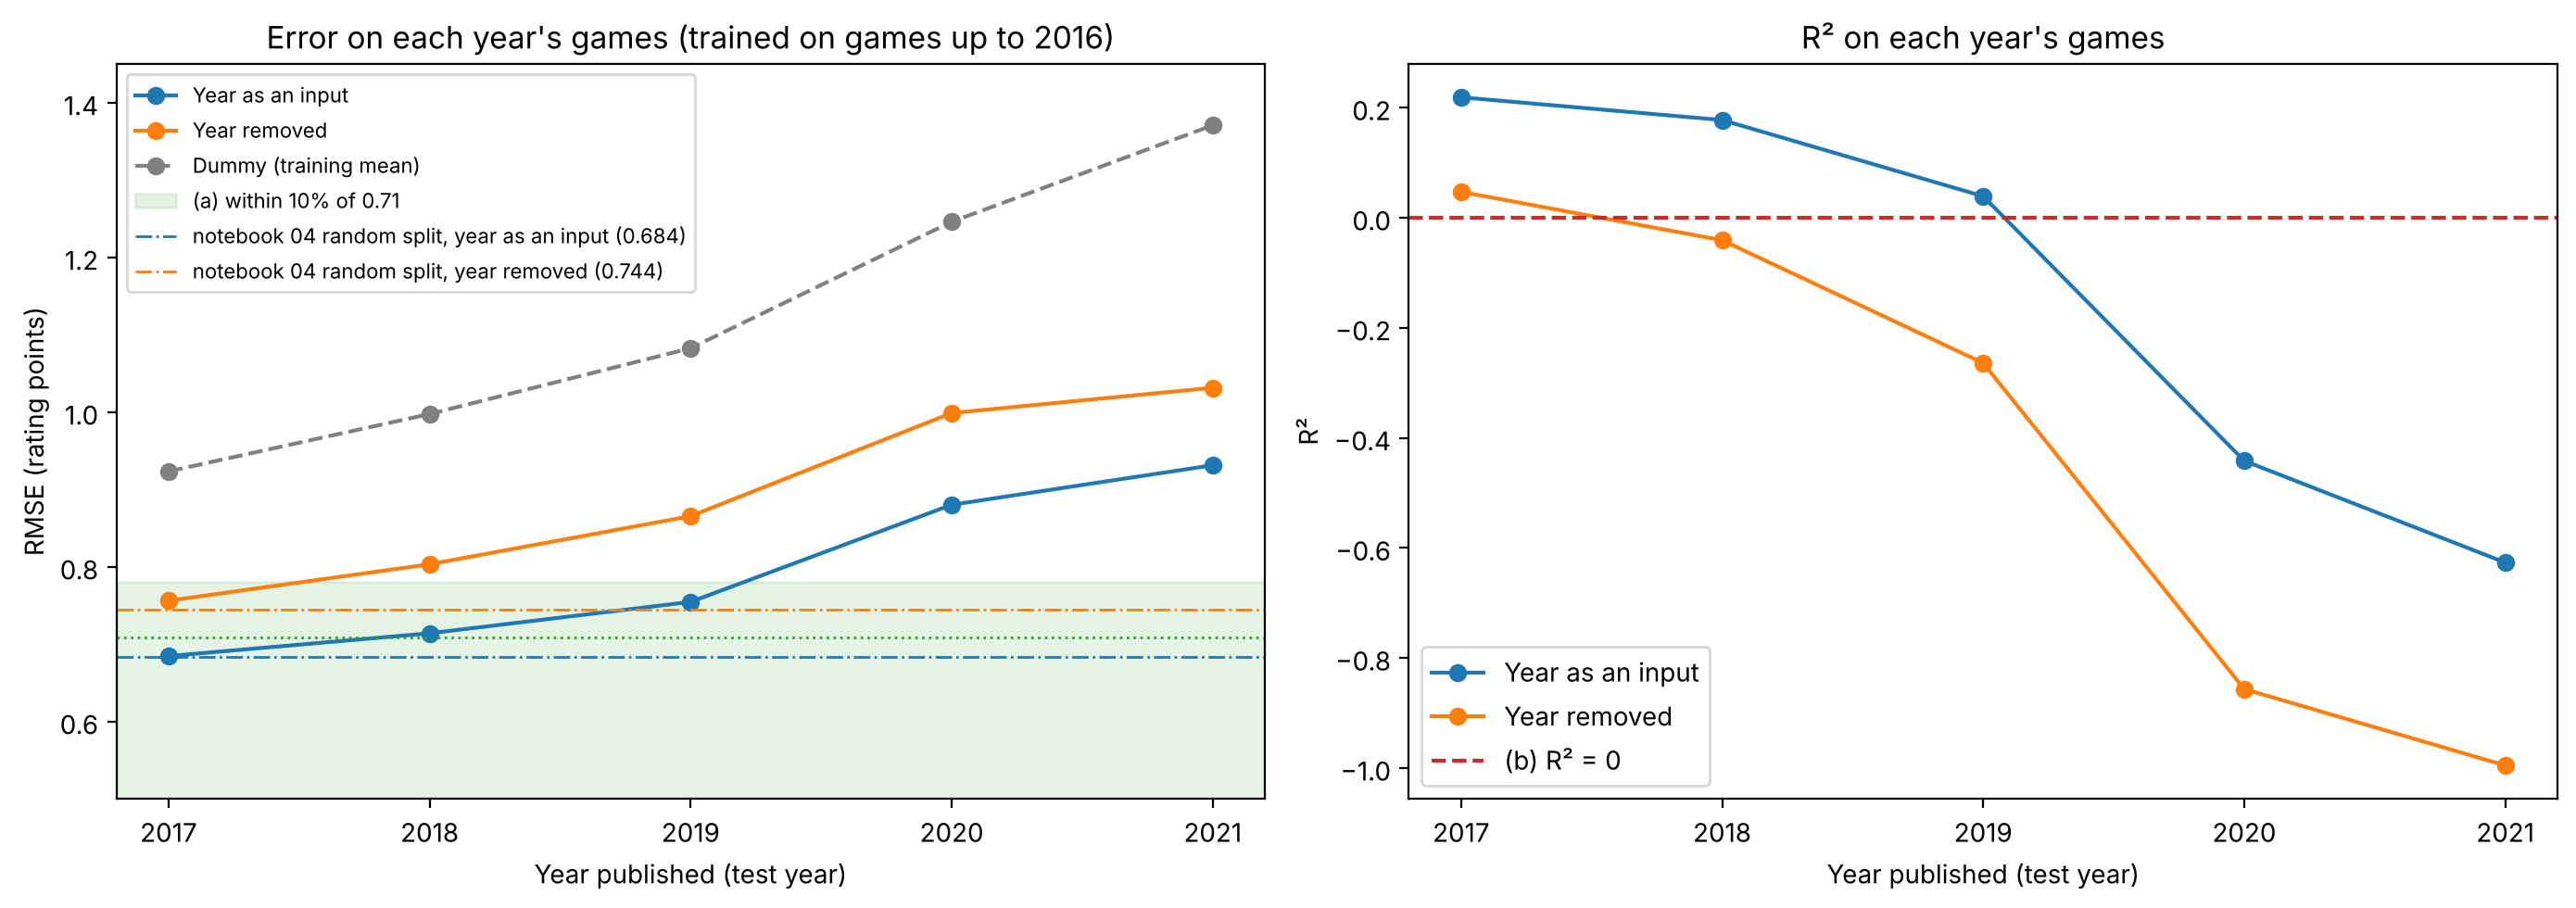

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-11. Figure: error and R² by test year, with both tests marked; reviewed and edited by Andrew Reicin.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
years = list(TEST_YEARS)

for name in versions:
    yr = by_year[by_year["model"] == name].set_index("test year")
    axes[0].plot(years, yr["RMSE"], marker="o", color=COLORS[name], label=name)
    axes[1].plot(years, yr["R2"], marker="o", color=COLORS[name], label=name)
dm = by_year[by_year["model"] == "Dummy (training mean)"].set_index("test year")
axes[0].plot(years, dm["RMSE"], marker="o", linestyle="--", color=COLORS["Dummy (training mean)"], label="Dummy (training mean)")

ref = reference["Year as an input"]
axes[0].axhspan(0, ref * (1 + THRESHOLD), color="tab:green", alpha=0.12, label=f"(a) within 10% of {ref:.2f}")
axes[0].axhline(y=ref, color="tab:green", linestyle=":", linewidth=1)
for name in versions:
    axes[0].axhline(y=NB04_RANDOM[name], color=COLORS[name], linestyle="-.", linewidth=1,
                    label=f"notebook 04 random split, {name.lower()} ({NB04_RANDOM[name]})")
axes[0].set_ylim(0.5, 1.45)
axes[0].set_title(f"Error on each year's games (trained on games up to {CUTOFF})")
axes[0].set_xlabel("Year published (test year)")
axes[0].set_ylabel("RMSE (rating points)")
axes[0].legend(loc="upper left", fontsize=8)

axes[1].axhline(y=0, color="tab:red", linestyle="--", label="(b) R² = 0")
axes[1].set_title("R² on each year's games")
axes[1].set_xlabel("Year published (test year)")
axes[1].set_ylabel("R²")
axes[1].legend(loc="lower left")
for ax in axes:
    ax.set_xticks(years)
plt.tight_layout()
save("08_validity_by_year.png")
plt.show()

- **With year: valid 3 years by both tests** (through 2019; in 2020 RMSE is +24% above the reference and R² falls to -0.44).
- **Without year: valid 1 year by both tests** (2018 misses the 10% limit by 0.001, so test (a) is on the edge there).
- **Against notebook 04's random split:** the year split matches it in 2017 (0.685 vs 0.684 with year; 0.756 vs 0.744 without), then is worse every year after, by 0.03 in 2018 rising to 0.25 in 2021. A random split mixes old and new games in both halves, so it does not show this decline. Notebook 04's numbers come from its own rows and tree (depth 10), so this is a rough comparison, not like for like.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-11. Sensitivity of test (a) to the threshold; reviewed and edited by Andrew Reicin.
ref = reference["Year as an input"]
yr = by_year[by_year["model"] == "Year as an input"].set_index("test year")["RMSE"]
rows = []
for t in [0.05, 0.10, 0.15, 0.20, 0.25]:
    ok = yr[yr <= ref * (1 + t)].index
    last_ok = max([y for y in TEST_YEARS if all(yy in ok for yy in range(TEST_YEARS[0], y + 1))], default=None)
    rows.append({"threshold": f"{t:.0%}", "RMSE limit": round(ref * (1 + t), 3), "valid through": last_ok,
                 "years valid": 0 if last_ok is None else last_ok - CUTOFF})
pd.DataFrame(rows).set_index("threshold")

,RMSE limit,valid through,years valid
threshold,,,
5%,0.744,2018,2
10%,0.780,2019,3
15%,0.815,2019,3
20%,0.851,2019,3
25%,0.886,2020,4


10% to 20% all give 3 years. 5% gives 2 years (2019 is +6%), and 25% gives 4.

## 5. Why the error grows: ratings keep rising

The average miss above is negative and grows each year. This compares the actual and predicted averages by year.

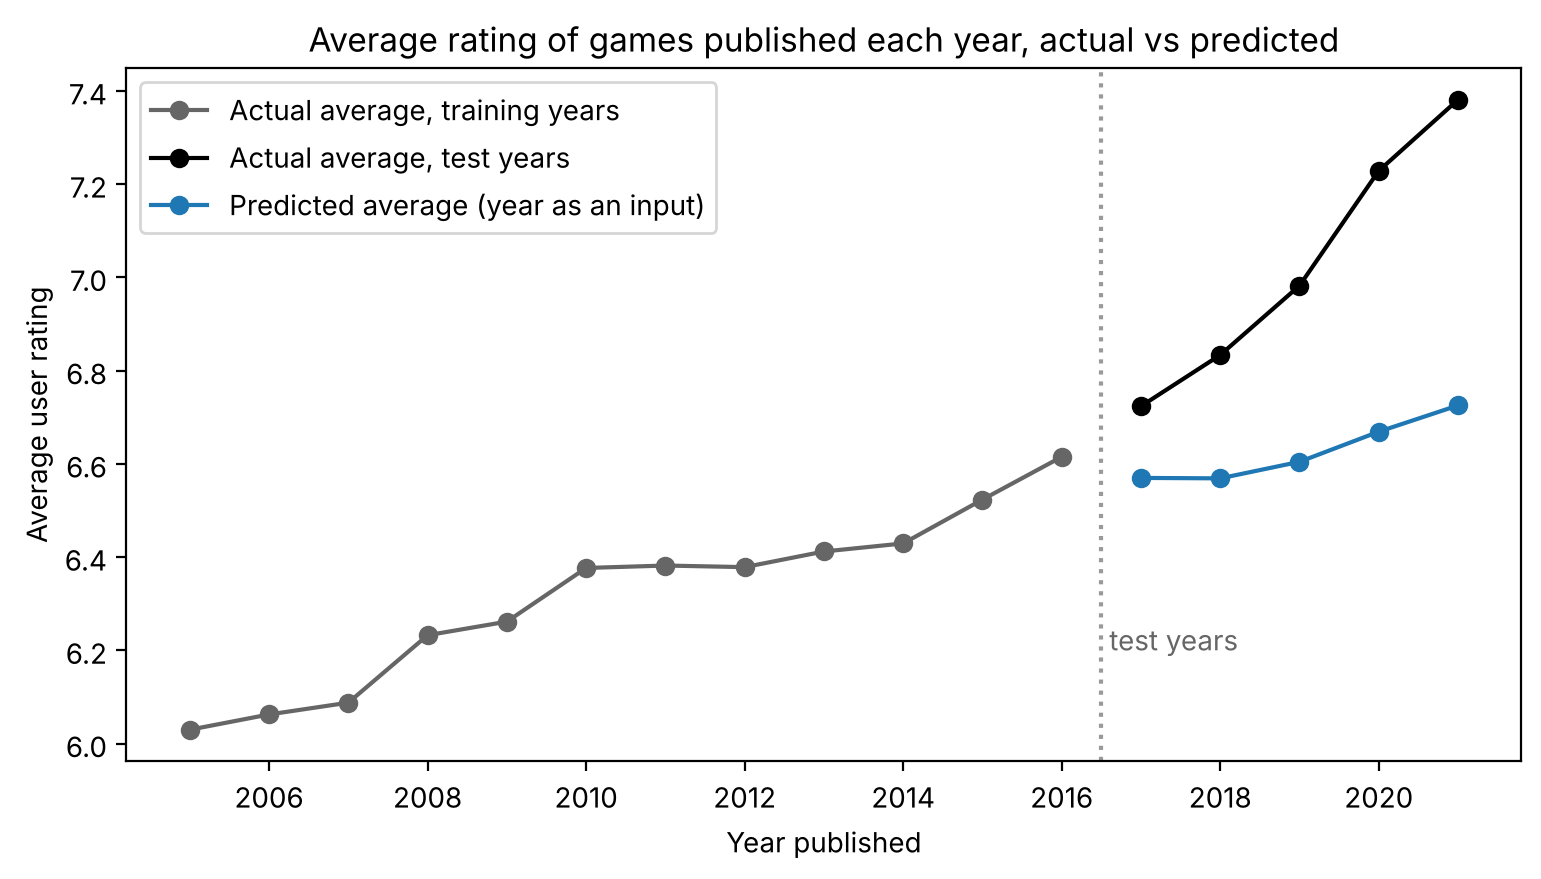

,games,average actual,average predicted,average miss (pred - actual)
test year,,,,
2017,1321,6.72,6.57,-0.15
2018,1318,6.83,6.57,-0.26
2019,1256,6.98,6.60,-0.38
2020,896,7.23,6.67,-0.56
2021,675,7.38,6.73,-0.66


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-11. Figure: actual vs predicted average rating by year; reviewed and edited by Andrew Reicin.
yr = by_year[by_year["model"] == "Year as an input"].set_index("test year")
train_by_year = train_df[train_df["yearpublished"] >= 2005].groupby("yearpublished")["average"].mean()

plt.figure(figsize=(9, 4.5))
plt.plot(train_by_year.index, train_by_year.values, marker="o", color="0.4", label="Actual average, training years")
plt.plot(yr.index, yr["average actual"], marker="o", color="black", label="Actual average, test years")
plt.plot(yr.index, yr["average predicted"], marker="o", color=COLORS["Year as an input"], label="Predicted average (year as an input)")
plt.axvline(x=CUTOFF + 0.5, color="0.6", linestyle=":")
plt.text(CUTOFF + 0.6, 6.2, "test years", color="0.4")
plt.title("Average rating of games published each year, actual vs predicted")
plt.xlabel("Year published")
plt.ylabel("Average user rating")
plt.legend(loc="upper left")
save("08_rating_drift.png")
plt.show()

yr[["games", "average actual", "average predicted", "average miss (pred - actual)"]].round(2)

Average ratings of newly published games rise every year (6.72 in 2017 to 7.38 in 2021), while the predictions stay between 6.57 and 6.73. The model cannot follow a rise it never saw in training.

## 6. Does year still help on games newer than any in training?

A tree cannot extrapolate: every test year is beyond the last split on year, so the model treats a 2021 game exactly like a 2016 game. The check below confirms that, then compares the two versions directly.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-11. Check: setting every test game's year to 2016 leaves the predictions unchanged; reviewed and edited by Andrew Reicin.
test_all = data[data["yearpublished"].isin(TEST_YEARS)]
X_test_all = build_inputs(test_all)
as_2016 = X_test_all.copy()
as_2016["yearpublished"] = CUTOFF
same = np.allclose(models["Year as an input"].predict(X_test_all), models["Year as an input"].predict(as_2016))
print("Predictions identical when every test game is set to", CUTOFF, ":", same)

Predictions identical when every test game is set to 2016 : True


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-11. Year in vs year removed, every test year; reviewed and edited by Andrew Reicin.
compare = by_year[by_year["model"] != "Dummy (training mean)"].pivot(index="test year", columns="model", values="RMSE")
compare["RMSE saved by keeping year"] = compare["Year removed"] - compare["Year as an input"]
compare["year helps"] = np.where(compare["RMSE saved by keeping year"] > 0, "yes", "no")
compare.round(3)

model,Year as an input,Year removed,RMSE saved by keeping year,year helps
test year,,,,
2017,0.685,0.756,0.072,yes
2018,0.714,0.803,0.089,yes
2019,0.755,0.865,0.111,yes
2020,0.880,0.999,0.119,yes
2021,0.931,1.031,0.100,yes


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-11. Where year sits in the tree: importance of each input; reviewed and edited by Andrew Reicin.
imp = pd.Series(models["Year as an input"].named_steps["model"].feature_importances_, index=versions["Year as an input"]).sort_values(ascending=False)
imp.head(8).round(3).to_frame("importance")

,importance
maxplaytime,0.329
yearpublished,0.221
mech_Roll / Spin and Move,0.145
n_mechanics,0.127
maxplayers,0.054
minage,0.041
cat_Wargame,0.024
mech_list_missing,0.014


- Year lowers the error in every test year, by 0.07 to 0.12, and is the second most important input (0.22, after maximum play time).
- The tree treats every game after 2016 as if published in 2016 (predictions unchanged), so year only marks a game as recent; it cannot follow the rising trend.

## 7. Summary

- **Valid about 3 years** with year as an input, by both tests; about 1 year without it.
- **Decision (Andrew Reicin): keep year as an input, with a caveat.** It improves the model in every test year, but only by marking games as recent; it cannot follow ratings that keep rising.
- **Limitation:** average ratings of newly published games rise each year, so a model trained on past games under-predicts newer ones, and its error grows within a few years of the training cut-off. Using it in practice would require regular retraining.

Rows, inputs and model are task 1's and task 10's (notebooks 05 and 13), not re-tuned, as the task says. Rowan's proposed minimum-ratings cut-off (notebook 14) is not applied, as it is not yet a group decision.